In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report

In [2]:
# Synthetic (computer-generated) flower dataset
df1 = pd.read_csv("flower_dataset.csv")
df1.head()

,flower_id,petal_length_cm,petal_width_cm,sepal_length_cm,sepal_width_cm,stem_height_cm,color,flower_type
0,1,6.2,3.0,2.6,1.1,61.5,orange,Rose
1,2,6.1,3.6,3.0,1.5,39.5,yellow,Tulip
2,3,6.4,3.8,3.7,0.6,41.6,red,Tulip
3,4,4.7,3.5,2.6,1.5,61.4,yellow,Rose
4,5,4.6,3.5,2.3,1.1,80.4,orange,Rose


In [3]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   flower_id        1000 non-null   int64  
 1   petal_length_cm  1000 non-null   float64
 2   petal_width_cm   1000 non-null   float64
 3   sepal_length_cm  1000 non-null   float64
 4   sepal_width_cm   1000 non-null   float64
 5   stem_height_cm   1000 non-null   float64
 6   color            1000 non-null   object 
 7   flower_type      1000 non-null   object 
dtypes: float64(5), int64(1), object(2)
memory usage: 62.6+ KB


In [4]:
df1.describe()

,flower_id,petal_length_cm,petal_width_cm,sepal_length_cm,sepal_width_cm,stem_height_cm
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,5.30640,3.320500,2.804000,1.391500,49.876300
std,288.819436,1.20135,0.716605,0.552946,0.313745,17.881317
min,1.000000,2.00000,1.400000,1.200000,0.500000,15.000000
25%,250.750000,4.50000,2.800000,2.400000,1.200000,37.600000
50%,500.500000,5.30000,3.300000,2.800000,1.400000,48.000000
75%,750.250000,6.10000,3.800000,3.200000,1.600000,61.500000
max,1000.000000,9.10000,5.700000,4.600000,2.700000,115.000000


In [5]:
df1.isnull().sum()

flower_id          0
petal_length_cm    0
petal_width_cm     0
sepal_length_cm    0
sepal_width_cm     0
stem_height_cm     0
color              0
flower_type        0
dtype: int64

In [6]:
df1.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   flower_id        1000 non-null   int64  
 1   petal_length_cm  1000 non-null   float64
 2   petal_width_cm   1000 non-null   float64
 3   sepal_length_cm  1000 non-null   float64
 4   sepal_width_cm   1000 non-null   float64
 5   stem_height_cm   1000 non-null   float64
 6   color            1000 non-null   str    
 7   flower_type      1000 non-null   str    
dtypes: float64(5), int64(1), str(2)
memory usage: 62.6 KB


In [7]:
df1.describe()

,flower_id,petal_length_cm,petal_width_cm,sepal_length_cm,sepal_width_cm,stem_height_cm
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,5.30640,3.320500,2.804000,1.391500,49.876300
std,288.819436,1.20135,0.716605,0.552946,0.313745,17.881317
min,1.000000,2.00000,1.400000,1.200000,0.500000,15.000000
25%,250.750000,4.50000,2.800000,2.400000,1.200000,37.600000
50%,500.500000,5.30000,3.300000,2.800000,1.400000,48.000000
75%,750.250000,6.10000,3.800000,3.200000,1.600000,61.500000
max,1000.000000,9.10000,5.700000,4.600000,2.700000,115.000000


In [8]:
df1.isnull().sum()

flower_id          0
petal_length_cm    0
petal_width_cm     0
sepal_length_cm    0
sepal_width_cm     0
stem_height_cm     0
color              0
flower_type        0
dtype: int64

In [9]:
df1.duplicated().sum()

np.int64(0)

In [10]:
df1.dtypes

flower_id            int64
petal_length_cm    float64
petal_width_cm     float64
sepal_length_cm    float64
sepal_width_cm     float64
stem_height_cm     float64
color                  str
flower_type            str
dtype: object

In [5]:
df1 = df1.drop_duplicates()

In [6]:
df1["flower_type"].value_counts()

flower_type
Tulip    509
Rose     491
Name: count, dtype: int64

In [7]:
df1["flower_type"] = df1["flower_type"].map({"Rose": 0, "Tulip": 1})

df1.head()

,flower_id,petal_length_cm,petal_width_cm,sepal_length_cm,sepal_width_cm,stem_height_cm,color,flower_type
0,1,6.2,3.0,2.6,1.1,61.5,orange,0
1,2,6.1,3.6,3.0,1.5,39.5,yellow,1
2,3,6.4,3.8,3.7,0.6,41.6,red,1
3,4,4.7,3.5,2.6,1.5,61.4,yellow,0
4,5,4.6,3.5,2.3,1.1,80.4,orange,0


In [8]:
df1 = df1.drop("flower_id", axis=1)

df1 = pd.get_dummies(df1, drop_first=True, dtype=int)

df1.head()

,petal_length_cm,petal_width_cm,sepal_length_cm,sepal_width_cm,stem_height_cm,flower_type,color_pink,color_red,color_yellow
0,6.2,3.0,2.6,1.1,61.5,0,0,0,0
1,6.1,3.6,3.0,1.5,39.5,1,0,0,1
2,6.4,3.8,3.7,0.6,41.6,1,0,1,0
3,4.7,3.5,2.6,1.5,61.4,0,0,0,1
4,4.6,3.5,2.3,1.1,80.4,0,0,0,0


In [9]:
X1 = df1.drop("flower_type", axis=1)
y1 = df1["flower_type"]

In [10]:
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42, stratify=y1
)
scaler1 = StandardScaler()

X1_train_scaled = scaler1.fit_transform(X1_train)
X1_test_scaled = scaler1.transform(X1_test)

In [11]:
model1 = LogisticRegression(max_iter=1000)

model1.fit(X1_train_scaled, y1_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [12]:
y1_pred = model1.predict(X1_test_scaled)

y1_pred[:10]

array([1, 0, 0, 1, 1, 1, 1, 1, 0, 0])

In [13]:
print("Accuracy:", accuracy_score(y1_test, y1_pred))
print("Precision:", precision_score(y1_test, y1_pred, zero_division=0))
print("Recall:", recall_score(y1_test, y1_pred, zero_division=0))
print("F1 Score:", f1_score(y1_test, y1_pred, zero_division=0))

Accuracy: 0.875
Precision: 0.8811881188118812
Recall: 0.8725490196078431
F1 Score: 0.8768472906403941


In [14]:
print(classification_report(y1_test, y1_pred))

              precision    recall  f1-score   support

           0       0.87      0.88      0.87        98
           1       0.88      0.87      0.88       102

    accuracy                           0.88       200
   macro avg       0.87      0.88      0.87       200
weighted avg       0.88      0.88      0.88       200



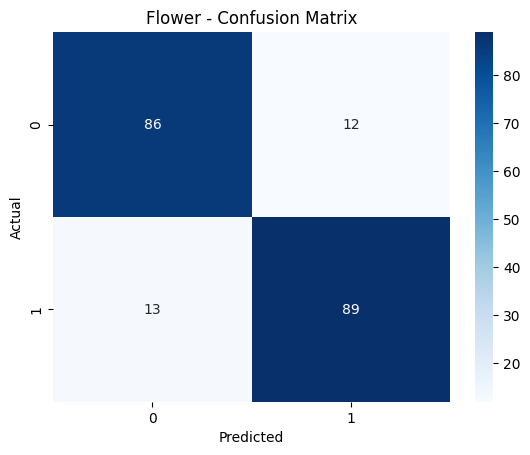

In [21]:
cm1 = confusion_matrix(y1_test, y1_pred)

sns.heatmap(cm1, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Flower - Confusion Matrix")
plt.show()

In [ ]:

df2 = pd.read_csv("laptop_battery_dataset.csv")
df2.head()

,laptop_id,brand,laptop_age_years,charge_cycles,daily_usage_hours,avg_battery_temp_c,needs_replacement
0,1,Dell,1.5,58,7.7,30.1,0
1,2,Dell,5.2,725,6.5,30.5,0
2,3,Dell,2.6,631,5.9,25.0,0
3,4,Lenovo,5.8,933,4.3,34.3,1
4,5,Asus,1.1,183,1.0,29.1,0


In [16]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   laptop_id           1500 non-null   int64  
 1   brand               1500 non-null   object 
 2   laptop_age_years    1500 non-null   float64
 3   charge_cycles       1500 non-null   int64  
 4   daily_usage_hours   1500 non-null   float64
 5   avg_battery_temp_c  1500 non-null   float64
 6   needs_replacement   1500 non-null   int64  
dtypes: float64(3), int64(3), object(1)
memory usage: 82.2+ KB


In [17]:
df2.describe()

,laptop_id,laptop_age_years,charge_cycles,daily_usage_hours,avg_battery_temp_c,needs_replacement
count,1500.000000,1500.00000,1500.000000,1500.000000,1500.000000,1500.000000
mean,750.500000,3.20460,606.207333,6.055067,36.302200,0.106667
std,433.157015,1.55904,340.955913,2.442056,5.218224,0.308792
min,1.000000,0.50000,20.000000,1.000000,25.000000,0.000000
25%,375.750000,1.80000,331.000000,4.300000,32.800000,0.000000
50%,750.500000,3.20000,570.500000,6.000000,36.300000,0.000000
75%,1125.250000,4.50000,837.250000,7.800000,39.700000,0.000000
max,1500.000000,6.00000,1832.000000,13.100000,52.600000,1.000000


In [18]:
df2.isnull().sum()

laptop_id             0
brand                 0
laptop_age_years      0
charge_cycles         0
daily_usage_hours     0
avg_battery_temp_c    0
needs_replacement     0
dtype: int64

In [19]:
df2.duplicated().sum()

np.int64(0)

In [20]:
df2.dtypes

laptop_id               int64
brand                  object
laptop_age_years      float64
charge_cycles           int64
daily_usage_hours     float64
avg_battery_temp_c    float64
needs_replacement       int64
dtype: object

In [21]:
df2 = df2.drop_duplicates()

In [22]:
df2 = df2.drop(columns=[
    "laptop_id"
])

In [23]:
df2 = pd.get_dummies(df2, columns=["brand"], drop_first=True, dtype=int)

df2.head()

,laptop_age_years,charge_cycles,daily_usage_hours,avg_battery_temp_c,needs_replacement,brand_Dell,brand_HP,brand_Lenovo
0,1.5,58,7.7,30.1,0,1,0,0
1,5.2,725,6.5,30.5,0,1,0,0
2,2.6,631,5.9,25.0,0,1,0,0
3,5.8,933,4.3,34.3,1,0,0,1
4,1.1,183,1.0,29.1,0,0,0,0


In [24]:
df2["needs_replacement"].value_counts()

needs_replacement
0    1340
1     160
Name: count, dtype: int64

In [25]:
X2 = df2.drop("needs_replacement", axis=1)
y2 = df2["needs_replacement"]

In [26]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)
scaler2 = StandardScaler()

X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

In [27]:
model2 = LogisticRegression(max_iter=1000, class_weight="balanced")

model2.fit(X2_train_scaled, y2_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [28]:
y2_pred = model2.predict(X2_test_scaled)

y2_pred[:10]

array([0, 0, 1, 1, 1, 0, 0, 0, 0, 1])

In [29]:
print("Accuracy:", accuracy_score(y2_test, y2_pred))
print("Precision:", precision_score(y2_test, y2_pred, zero_division=0))
print("Recall:", recall_score(y2_test, y2_pred, zero_division=0))
print("F1 Score:", f1_score(y2_test, y2_pred, zero_division=0))

Accuracy: 0.8033333333333333
Precision: 0.3373493975903614
Recall: 0.875
F1 Score: 0.48695652173913045


In [30]:
print(classification_report(y2_test, y2_pred))

              precision    recall  f1-score   support

           0       0.98      0.79      0.88       268
           1       0.34      0.88      0.49        32

    accuracy                           0.80       300
   macro avg       0.66      0.83      0.68       300
weighted avg       0.91      0.80      0.84       300



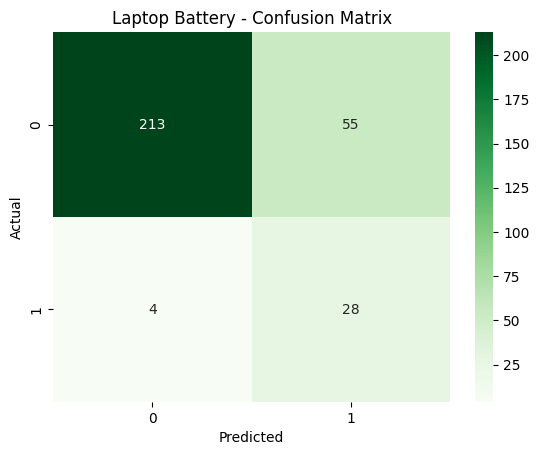

In [38]:
cm2 = confusion_matrix(y2_test, y2_pred)

sns.heatmap(cm2, annot=True, fmt="d", cmap="Greens")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Laptop Battery - Confusion Matrix")
plt.show()

In [ ]:
!pip install gradio -q

In [31]:
import gradio as gr

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [32]:
def predict_flower(color, petal_length, petal_width,
                   sepal_length, sepal_width, stem_height):

    data = pd.DataFrame(0, index=[0], columns=X1.columns)

    data["petal_length_cm"] = petal_length
    data["petal_width_cm"] = petal_width
    data["sepal_length_cm"] = sepal_length
    data["sepal_width_cm"] = sepal_width
    data["stem_height_cm"] = stem_height

    if color == "pink" and "color_pink" in data.columns:
        data["color_pink"] = 1

    elif color == "red" and "color_red" in data.columns:
        data["color_red"] = 1

    elif color == "yellow" and "color_yellow" in data.columns:
        data["color_yellow"] = 1

    data_scaled = scaler1.transform(data)

    prediction = model1.predict(data_scaled)[0]

    if prediction == 1:
        return "Tulip Predicted"
    else:
        return "Rose Predicted"


def predict_laptop(brand, laptop_age, charge_cycles,
                   daily_usage, battery_temp):

    data = pd.DataFrame(0, index=[0], columns=X2.columns)

    data["laptop_age_years"] = laptop_age
    data["charge_cycles"] = charge_cycles
    data["daily_usage_hours"] = daily_usage
    data["avg_battery_temp_c"] = battery_temp

    if brand == "Dell" and "brand_Dell" in data.columns:
        data["brand_Dell"] = 1

    elif brand == "HP" and "brand_HP" in data.columns:
        data["brand_HP"] = 1

    elif brand == "Lenovo" and "brand_Lenovo" in data.columns:
        data["brand_Lenovo"] = 1

    data_scaled = scaler2.transform(data)

    prediction = model2.predict(data_scaled)[0]

    if prediction == 1:
        return "Battery Needs Replacement"
    else:
        return "Battery Is Fine"

In [33]:
with gr.Blocks(title="ANN Lab Task 2") as demo:

    gr.Markdown("# Logistic Regression Classification")
    gr.Markdown("Flower Classification and Laptop Battery Prediction")

    with gr.Tab("Flower"):

        color = gr.Dropdown(
            ["red", "pink", "yellow", "orange"],
            label="Flower Color",
            value="red"
        )
        petal_length = gr.Number(
            label="Petal Length (cm)", value=5
        )
        petal_width = gr.Number(
            label="Petal Width (cm)", value=3.3
        )
        sepal_length = gr.Number(
            label="Sepal Length (cm)", value=2.8
        )
        sepal_width = gr.Number(
            label="Sepal Width (cm)", value=1.4
        )
        stem_height = gr.Number(
            label="Stem Height (cm)", value=50
        )

        flower_button = gr.Button("Predict Flower")
        flower_output = gr.Textbox(label="Prediction")

        flower_button.click(
            fn=predict_flower,
            inputs=[
                color, petal_length, petal_width,
                sepal_length, sepal_width, stem_height
            ],
            outputs=flower_output
        )

    with gr.Tab("Laptop Battery"):

        brand = gr.Dropdown(
            ["Dell", "HP", "Lenovo", "Asus"],
            label="Laptop Brand",
            value="Dell"
        )
        laptop_age = gr.Number(
            label="Laptop Age (years)", value=3
        )
        charge_cycles = gr.Number(
            label="Charge Cycles", value=600
        )
        daily_usage = gr.Number(
            label="Daily Usage (hours)", value=6
        )
        battery_temp = gr.Number(
            label="Average Battery Temperature (C)", value=36
        )

        laptop_button = gr.Button("Predict Battery Condition")
        laptop_output = gr.Textbox(label="Prediction")

        laptop_button.click(
            fn=predict_laptop,
            inputs=[
                brand, laptop_age, charge_cycles,
                daily_usage, battery_temp
            ],
            outputs=laptop_output
        )

demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7861

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


In [38]:
%pip install flask pyngrok -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
from flask import Flask, request, render_template_string
from threading import Thread

In [41]:
app = Flask(__name__)

html = """
<!DOCTYPE html>
<html>
<head>
    <title>ANN Lab Task 2</title>
    <style>
        body {
            font-family: Arial;
            background: #f0f4f8;
            padding: 30px;
        }
        .container {
            background: white;
            max-width: 600px;
            margin: auto;
            padding: 30px;
            border-radius: 12px;
            box-shadow: 0 4px 15px #ddd;
        }
        h1 { text-align: center; color: #243b53; }
        h2 { color: #334e68; }
        label { display: block; margin-top: 12px; }
        input, select {
            width: 100%;
            padding: 10px;
            margin-top: 5px;
            box-sizing: border-box;
        }
        button {
            background: #2563eb;
            color: white;
            padding: 12px;
            border: none;
            width: 100%;
            margin-top: 20px;
            cursor: pointer;
            border-radius: 6px;
        }
        .result {
            margin-top: 20px;
            padding: 15px;
            background: #dbeafe;
            border-radius: 6px;
        }
        hr { margin: 30px 0; }
    </style>
</head>
<body>
<div class="container">
    <h1>Logistic Regression Classification</h1>
    <p style="text-align:center;">ANN Lab Task 2</p>

    <h2>Flower Prediction</h2>
    <form method="POST">
        <input type="hidden" name="model" value="flower">

        <label>Flower Color</label>
        <select name="color">
            <option>red</option>
            <option>pink</option>
            <option>yellow</option>
            <option>orange</option>
        </select>

        <label>Petal Length (cm)</label>
        <input type="number" step="any" name="petal_length" value="5" required>

        <label>Petal Width (cm)</label>
        <input type="number" step="any" name="petal_width" value="3.3" required>

        <label>Sepal Length (cm)</label>
        <input type="number" step="any" name="sepal_length" value="2.8" required>

        <label>Sepal Width (cm)</label>
        <input type="number" step="any" name="sepal_width" value="1.4" required>

        <label>Stem Height (cm)</label>
        <input type="number" step="any" name="stem_height" value="50" required>

        <button type="submit">Predict Flower</button>
    </form>

    <hr>

    <h2>Laptop Battery Prediction</h2>
    <form method="POST">
        <input type="hidden" name="model" value="laptop">

        <label>Laptop Brand</label>
        <select name="brand">
            <option>Dell</option>
            <option>HP</option>
            <option>Lenovo</option>
            <option>Asus</option>
        </select>

        <label>Laptop Age (years)</label>
        <input type="number" step="any" name="laptop_age" value="3" required>

        <label>Charge Cycles</label>
        <input type="number" name="charge_cycles" value="600" required>

        <label>Daily Usage (hours)</label>
        <input type="number" step="any" name="daily_usage" value="6" required>

        <label>Average Battery Temperature (C)</label>
        <input type="number" step="any" name="battery_temp" value="36" required>

        <button type="submit">Predict Battery Condition</button>
    </form>

    {% if result %}
        <div class="result">
            <strong>Prediction:</strong> {{ result }}
        </div>
    {% endif %}
</div>
</body>
</html>
"""

@app.route("/", methods=["GET", "POST"])
def home():
    result = None

    if request.method == "POST":

        if request.form["model"] == "flower":
            result = predict_flower(
                request.form["color"],
                float(request.form["petal_length"]),
                float(request.form["petal_width"]),
                float(request.form["sepal_length"]),
                float(request.form["sepal_width"]),
                float(request.form["stem_height"])
            )

        elif request.form["model"] == "laptop":
            result = predict_laptop(
                request.form["brand"],
                float(request.form["laptop_age"]),
                float(request.form["charge_cycles"]),
                float(request.form["daily_usage"]),
                float(request.form["battery_temp"])
            )

    return render_template_string(html, result=result)

In [42]:
def run_flask():
    app.run(port=5000, use_reloader=False)

Thread(target=run_flask, daemon=True).start()

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
127.0.0.1 - - [13/Oct/2026 12:43:25] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [13/Oct/2026 12:43:25] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [13/Oct/2026 12:43:44] "POST / HTTP/1.1" 200 -
127.0.0.1 - - [13/Oct/2026 12:43:48] "POST / HTTP/1.1" 200 -
127.0.0.1 - - [13/Oct/2026 12:44:11] "POST / HTTP/1.1" 200 -


In [43]:
print("Flask Website: http://127.0.0.1:5000")

Flask Website: http://127.0.0.1:5000
